# Dimensionality reduction with PCA: built from scratch, then compared with scikit-learn and t-SNE
### A mini Pokémon image set

**The idea in one sentence:** every image is just a long list of numbers (one per pixel).
PCA finds the *few* directions along which the images differ the most, so we can describe each
image with 2 or 10 numbers instead of 1,728, and still recognise it.

**How this notebook is organised**

| Part | What happens | Tools | Live coding? |
|---|---|---|---|
| **A. PCA from scratch** | formulas, a tiny worked example by hand, then centre → covariance → eigenvectors → project → reconstruct on the images | **NumPy only** | **Yes** |
| **B. Comparative study** | prove our PCA matches scikit-learn, compare with t-SNE, see when PCA fails | scikit-learn | No, just run |
| **C. Application** | the same PCA on cybersecurity-style network data | NumPy | Optional |

> **Be realistic:** our images have different backgrounds (grass, sky, white...). PCA only looks at
> pixel values, so it will partly group by *colour and background*, not by "which Pokémon is this".
> That is not a bug, it is exactly what PCA does, and it is a good thing to discuss.

---
# Part A: PCA from scratch (NumPy only)
No scikit-learn anywhere in this part. Everything is built with plain NumPy, step by step.

## A0: Setup
Only NumPy and Matplotlib (plus our small image helper, which uses Pillow to open and resize pictures).
Run this notebook from the project folder so that `pokemon_images/` and `pre_process_image.py` are found.

In [1]:
# A0: imports and settings (NumPy + Matplotlib only)
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

from pre_process_image import pre_process_image       # our helper: fixes transparency + resizes

IMAGE_DIR = Path("pokemon_images")   # one sub-folder per Pokémon
IMAGE_SIZE = 24                      # every image becomes 24 x 24 pixels
N_PER_SPECIES = 6                    # "a few" images per Pokémon
RANDOM_STATE = 42

# one fixed colour per Pokémon, used in every plot
COLORS = {"bulbasaur": "#2e9e6a", "charmander": "#e8702a", "pikachu": "#d9a600"}

print("Settings ready. Image size:", IMAGE_SIZE, "x", IMAGE_SIZE)

Settings ready. Image size: 24 x 24


## A1: The PCA recipe: every step and its formula
Notation: **n** = number of images (rows), **p** = number of pixel values per image (columns),
so the data matrix **X** is *n × p*.

| # | Step | Formula | NumPy |
|---|---|---|---|
| 1 | Data matrix | $X \in \mathbb{R}^{n \times p}$, row $i$ = image $i$ | `X = images.reshape(n, -1)` |
| 2 | Mean of every column | $\mu_j = \dfrac{1}{n}\sum_{i=1}^{n} x_{ij}$ | `mean = X.mean(axis=0)` |
| 3 | Centre the data | $X_c = X - \mathbf{1}\mu^{\top}$ | `Xc = X - mean` |
| 4 | Covariance matrix | $C = \dfrac{1}{n-1}\,X_c^{\top}X_c$  (size $p \times p$) | `C = Xc.T @ Xc / (n - 1)` |
| 5 | Eigen-decomposition | $C\,v_k = \lambda_k\,v_k$, found from $\det(C - \lambda I) = 0$ | `vals, vecs = np.linalg.eigh(C)` |
| 6 | Sort, keep the top k | $\lambda_1 \ge \lambda_2 \ge \dots$ and $W = [v_1 \; v_2 \; \dots \; v_k]$ | `np.argsort(vals)[::-1]` |
| 7 | Explained variance ratio | $\mathrm{EVR}_k = \dfrac{\lambda_k}{\sum_j \lambda_j}$ | `vals / vals.sum()` |
| 8 | Scores (new coordinates) | $Z = X_c\,W$  (size $n \times k$) | `Z = Xc @ W` |
| 9 | Reconstruction | $\hat{X} = \mathbf{1}\mu^{\top} + Z\,W^{\top}$ | `Xhat = mean + Z @ W.T` |

**Shortcut with SVD:** write $X_c = U\,S\,V^{\top}$. The columns of $V$ are the same eigenvectors and
$\lambda_k = s_k^2/(n-1)$. We check both routes in A7.

**Two words to keep apart:**
- **Loadings** (the eigenvectors, columns of $W$) say *what each principal component means*.
- **Scores** (the rows of $Z$) say *where each image sits* on the PC1 / PC2 graph.

Next we run all nine steps **by hand on a tiny example**, where every number fits on the screen.
After that we repeat exactly the same steps on the Pokémon images.

## A2: The whole algorithm on a tiny example (by hand)
Take **5 mini-images that have only 2 pixels each** (brightness from 0 to 10).
With 2 pixels, every image is a point on an ordinary x-y graph, so we can *see* every step.
With 1,728 pixels the picture would have 1,728 axes, which is why PCA is needed.

### A2.1 The data matrix X

X  (5 images x 2 pixels):
[[ 2.  2.]
 [ 4.  5.]
 [ 6.  4.]
 [ 8.  7.]
 [10.  7.]]


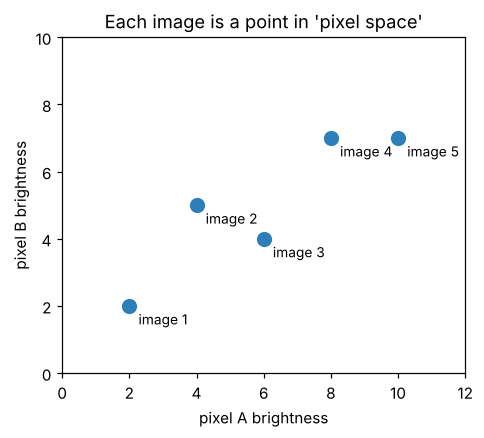

In [2]:
# A2.1: five mini-images, each with only 2 pixels (brightness 0-10)
tiny = np.array([[2, 2],
                 [4, 5],
                 [6, 4],
                 [8, 7],
                 [10, 7]], dtype=float)
n_tiny = len(tiny)

print("X  (5 images x 2 pixels):")
print(tiny)

fig, ax = plt.subplots(figsize=(4.5, 4.2))
ax.scatter(tiny[:, 0], tiny[:, 1], s=80, color="#2c7fb8")
for i, (a, b) in enumerate(tiny, start=1):
    ax.annotate(f"image {i}", (a, b), textcoords="offset points", xytext=(6, -12), fontsize=9)
ax.set_xlabel("pixel A brightness")
ax.set_ylabel("pixel B brightness")
ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.set_aspect("equal")
ax.set_title("Each image is a point in 'pixel space'")
plt.tight_layout()
plt.show()

### A2.2 Mean and centring
$$\mu_j = \frac{1}{n}\sum_{i=1}^{n} x_{ij} \qquad\qquad X_c = X - \mathbf{1}\mu^{\top}$$

In [3]:
# A2.2: mean of each pixel (column), then subtract it from every image
mu = tiny.mean(axis=0)
Xc_t = tiny - mu

print(f"mean of pixel A = ({' + '.join(f'{v:g}' for v in tiny[:, 0])}) / {n_tiny} = {mu[0]:g}")
print(f"mean of pixel B = ({' + '.join(f'{v:g}' for v in tiny[:, 1])}) / {n_tiny} = {mu[1]:g}")
print()
print("X_c = X - mean   (each row is now 'how this image differs from the average'):")
print(Xc_t)
print()
print("Column sums of X_c (must be 0):", Xc_t.sum(axis=0))

mean of pixel A = (2 + 4 + 6 + 8 + 10) / 5 = 6
mean of pixel B = (2 + 5 + 4 + 7 + 7) / 5 = 5

X_c = X - mean   (each row is now 'how this image differs from the average'):
[[-4. -3.]
 [-2.  0.]
 [ 0. -1.]
 [ 2.  2.]
 [ 4.  2.]]

Column sums of X_c (must be 0): [0. 0.]


### A2.3 Covariance matrix
$$\mathrm{var}(A)=\frac{\sum_i (a_i-\bar a)^2}{n-1},\qquad
\mathrm{cov}(A,B)=\frac{\sum_i (a_i-\bar a)(b_i-\bar b)}{n-1},\qquad
C=\begin{pmatrix}\mathrm{var}(A) & \mathrm{cov}(A,B)\\ \mathrm{cov}(A,B) & \mathrm{var}(B)\end{pmatrix}$$

A **positive covariance** means the two pixels tend to get brighter *together*.
In matrix form this is one multiplication: $C = \frac{1}{n-1}X_c^{\top}X_c$.

In [4]:
# A2.3: covariance, first term by term, then as one matrix product
dx, dy = Xc_t[:, 0], Xc_t[:, 1]

print(f"{'image':<7}{'dx':>6}{'dy':>6}{'dx*dx':>8}{'dy*dy':>8}{'dx*dy':>8}")
for i in range(n_tiny):
    print(f"{i + 1:<7}{dx[i]:>6.1f}{dy[i]:>6.1f}{dx[i] * dx[i]:>8.1f}{dy[i] * dy[i]:>8.1f}{dx[i] * dy[i] + 0.0:>8.1f}")
sum_aa, sum_bb, sum_ab = (dx * dx).sum(), (dy * dy).sum(), (dx * dy).sum()
print(f"{'sum':<7}{'':>12}{sum_aa:>8.1f}{sum_bb:>8.1f}{sum_ab:>8.1f}")
print()

var_a, var_b, cov_ab = sum_aa / (n_tiny - 1), sum_bb / (n_tiny - 1), sum_ab / (n_tiny - 1)
print(f"var(A)    = {sum_aa:.1f} / {n_tiny - 1} = {var_a:.2f}")
print(f"var(B)    = {sum_bb:.1f} / {n_tiny - 1} = {var_b:.2f}")
print(f"cov(A, B) = {sum_ab:.1f} / {n_tiny - 1} = {cov_ab:.2f}")

C_t = np.array([[var_a, cov_ab],
                [cov_ab, var_b]])
print()
print("C =")
print(C_t)

print()
print("The same thing as one matrix product, X_c^T (2x5) times X_c (5x2):")
print(Xc_t.T @ Xc_t)
print("divided by (n - 1) =", n_tiny - 1, "gives the same C?", np.allclose(Xc_t.T @ Xc_t / (n_tiny - 1), C_t))

image      dx    dy   dx*dx   dy*dy   dx*dy
1        -4.0  -3.0    16.0     9.0    12.0
2        -2.0   0.0     4.0     0.0     0.0
3         0.0  -1.0     0.0     1.0     0.0
4         2.0   2.0     4.0     4.0     4.0
5         4.0   2.0    16.0     4.0     8.0
sum                    40.0    18.0    24.0

var(A)    = 40.0 / 4 = 10.00
var(B)    = 18.0 / 4 = 4.50
cov(A, B) = 24.0 / 4 = 6.00

C =
[[10.   6. ]
 [ 6.   4.5]]

The same thing as one matrix product, X_c^T (2x5) times X_c (5x2):
[[40. 24.]
 [24. 18.]]
divided by (n - 1) = 4 gives the same C? True


### A2.4 Eigenvalues: solve by hand
We look for the numbers $\lambda$ with $\det(C-\lambda I)=0$. For a 2 × 2 matrix with entries $a, b, b, d$ this is just a quadratic equation:
$$\lambda^2-(a+d)\,\lambda+(ad-b^2)=0 \quad\Rightarrow\quad
\lambda=\frac{\mathrm{tr}\pm\sqrt{\mathrm{tr}^2-4\det}}{2},\qquad \mathrm{tr}=a+d,\ \det=ad-b^2$$

In [5]:
# A2.4: eigenvalues from the quadratic formula
a, b, d = C_t[0, 0], C_t[0, 1], C_t[1, 1]
trace = a + d
det = a * d - b * b
disc = np.sqrt(trace ** 2 - 4 * det)
lam1 = (trace + disc) / 2
lam2 = (trace - disc) / 2

print(f"trace = {a:.2f} + {d:.2f} = {trace:.2f}")
print(f"det   = {a:.2f} * {d:.2f} - {b:.2f}^2 = {det:.2f}")
print(f"equation: lambda^2 - {trace:.2f} lambda + {det:.2f} = 0")
print(f"sqrt(trace^2 - 4 det) = sqrt({trace ** 2:.2f} - {4 * det:.2f}) = {disc:.4f}")
print(f"lambda1 = ({trace:.2f} + {disc:.4f}) / 2 = {lam1:.4f}")
print(f"lambda2 = ({trace:.2f} - {disc:.4f}) / 2 = {lam2:.4f}")
print()
print("NumPy's answer:", np.round(np.sort(np.linalg.eigvalsh(C_t))[::-1], 4))
print(f"lambda1 + lambda2 = {lam1 + lam2:.4f}  =  trace = {trace:.4f}  (the total variance is kept)")

trace = 10.00 + 4.50 = 14.50
det   = 10.00 * 4.50 - 6.00^2 = 9.00
equation: lambda^2 - 14.50 lambda + 9.00 = 0
sqrt(trace^2 - 4 det) = sqrt(210.25 - 36.00) = 13.2004
lambda1 = (14.50 + 13.2004) / 2 = 13.8502
lambda2 = (14.50 - 13.2004) / 2 = 0.6498

NumPy's answer: [13.8502  0.6498]
lambda1 + lambda2 = 14.5000  =  trace = 14.5000  (the total variance is kept)


### A2.5 Eigenvectors: solve by hand
For each $\lambda$ we solve $(C-\lambda I)\,v=0$. The first row of that system says
$(a-\lambda)\,v_x + b\,v_y = 0$, which is satisfied by $v \propto (b,\ \lambda - a)$.
Finally we divide by the length so that $\lVert v \rVert = 1$.

In [6]:
# A2.5: eigenvectors, then check C v = lambda v
def eigenvector_2x2(lam):
    raw = np.array([b, lam - a])                    # solves (a - lam) vx + b vy = 0
    return raw, raw / np.linalg.norm(raw)

raw1, v1_t = eigenvector_2x2(lam1)
raw2, v2_t = eigenvector_2x2(lam2)

print(f"v1 (before scaling) = [b, lambda1 - a] = [{raw1[0]:.3f}, {raw1[1]:.3f}],  length = {np.linalg.norm(raw1):.3f}")
print(f"v1 = {np.round(v1_t, 3)}")
print(f"v2 (before scaling) = [b, lambda2 - a] = [{raw2[0]:.3f}, {raw2[1]:.3f}],  length = {np.linalg.norm(raw2):.3f}")
print(f"v2 = {np.round(v2_t, 3)}")
print()
print("Check  C v1 =", np.round(C_t @ v1_t, 3), "  lambda1 * v1 =", np.round(lam1 * v1_t, 3))
print("Check  C v2 =", np.round(C_t @ v2_t, 3), "  lambda2 * v2 =", np.round(lam2 * v2_t, 3))
print(f"v1 . v2 = {abs(float(v1_t @ v2_t)):.6f}   -> the two directions are perpendicular")

W_t = np.column_stack([v1_t, v2_t])                # W: one eigenvector per column
print()
print("W = [v1 v2] =")
print(np.round(W_t, 3))
print("(The sign of a vector is arbitrary: v and -v describe the same direction.)")

v1 (before scaling) = [b, lambda1 - a] = [6.000, 3.850],  length = 7.129
v1 = [0.842 0.54 ]
v2 (before scaling) = [b, lambda2 - a] = [6.000, -9.350],  length = 11.110
v2 = [ 0.54  -0.842]

Check  C v1 = [11.657  7.48 ]   lambda1 * v1 = [11.657  7.48 ]
Check  C v2 = [ 0.351 -0.547]   lambda2 * v2 = [ 0.351 -0.547]
v1 . v2 = 0.000000   -> the two directions are perpendicular

W = [v1 v2] =
[[ 0.842  0.54 ]
 [ 0.54  -0.842]]
(The sign of a vector is arbitrary: v and -v describe the same direction.)


### A2.6 Explained variance
$$\mathrm{EVR}_k=\frac{\lambda_k}{\lambda_1+\lambda_2}$$

In [7]:
# A2.6: how much of the total variation does each component carry?
total = lam1 + lam2
print(f"PC1: {lam1:.3f} / {total:.3f} = {lam1 / total * 100:.1f}%")
print(f"PC2: {lam2:.3f} / {total:.3f} = {lam2 / total * 100:.1f}%")

PC1: 13.850 / 14.500 = 95.5%
PC2: 0.650 / 14.500 = 4.5%


### A2.7 Scores: the new coordinates
$$z_{i1}=(x_i-\mu)\cdot v_1 \qquad z_{i2}=(x_i-\mu)\cdot v_2 \qquad\text{or all at once:}\qquad Z = X_c\,W$$

In [8]:
# A2.7: scores, written out for every image, then as one matrix product
for i in range(n_tiny):
    z1 = dx[i] * v1_t[0] + dy[i] * v1_t[1]
    z2 = dx[i] * v2_t[0] + dy[i] * v2_t[1]
    print(f"image {i + 1}:  z1 = ({dx[i]:+.0f})({v1_t[0]:.3f}) + ({dy[i]:+.0f})({v1_t[1]:.3f}) = {z1:+.3f}"
          f"     z2 = ({dx[i]:+.0f})({v2_t[0]:+.3f}) + ({dy[i]:+.0f})({v2_t[1]:+.3f}) = {z2:+.3f}")

Z_t = Xc_t @ W_t
print()
print("Z = X_c @ W   (5x2 times 2x2 = 5x2):")
print(np.round(Z_t, 3))
print()
print("Variance of the PC1 / PC2 scores:", np.round(Z_t.var(axis=0, ddof=1), 4), " -> equals the eigenvalues", np.round([lam1, lam2], 4))
print(f"Correlation between PC1 and PC2 scores: {abs(np.corrcoef(Z_t.T)[0, 1]):.6f}  -> the new axes are uncorrelated")

image 1:  z1 = (-4)(0.842) + (-3)(0.540) = -4.987     z2 = (-4)(+0.540) + (-3)(-0.842) = +0.365
image 2:  z1 = (-2)(0.842) + (+0)(0.540) = -1.683     z2 = (-2)(+0.540) + (+0)(-0.842) = -1.080
image 3:  z1 = (+0)(0.842) + (-1)(0.540) = -0.540     z2 = (+0)(+0.540) + (-1)(-0.842) = +0.842
image 4:  z1 = (+2)(0.842) + (+2)(0.540) = +2.763     z2 = (+2)(+0.540) + (+2)(-0.842) = -0.603
image 5:  z1 = (+4)(0.842) + (+2)(0.540) = +4.447     z2 = (+4)(+0.540) + (+2)(-0.842) = +0.477

Z = X_c @ W   (5x2 times 2x2 = 5x2):
[[-4.987  0.365]
 [-1.683 -1.08 ]
 [-0.54   0.842]
 [ 2.763 -0.603]
 [ 4.447  0.477]]

Variance of the PC1 / PC2 scores: [13.8502  0.6498]  -> equals the eigenvalues [13.8502  0.6498]
Correlation between PC1 and PC2 scores: 0.000000  -> the new axes are uncorrelated


### A2.8 Reconstruction: what do we lose if we keep only PC1?
$$\hat{X}=\mathbf{1}\mu^{\top}+Z_k\,W_k^{\top}$$

In [9]:
# A2.8: rebuild the 2-pixel images from ONE number each (k = 1), then from both (k = 2)
recon_1 = mu + Z_t[:, :1] @ W_t[:, :1].T
error_1 = tiny - recon_1

print(f"{'image':<7}{'original':>16}{'rebuilt (k=1)':>18}{'error':>16}")
for i in range(n_tiny):
    print(f"{i + 1:<7}{str(tiny[i]):>16}{str(np.round(recon_1[i], 2)):>18}{str(np.round(error_1[i], 2)):>16}")

print()
print(f"Sum of squared errors with k = 1 : {(error_1 ** 2).sum():.4f}")
print(f"(n - 1) * lambda2                 : {(n_tiny - 1) * lam2:.4f}   -> what we throw away is exactly the PC2 variance")

recon_2 = mu + Z_t @ W_t.T
print()
print("With k = 2 the rebuilt images equal the originals?", np.allclose(recon_2, tiny))

image          original     rebuilt (k=1)           error
1               [2. 2.]       [1.8  2.31]   [ 0.2  -0.31]
2               [4. 5.]       [4.58 4.09]   [-0.58  0.91]
3               [6. 4.]       [5.55 4.71]   [ 0.45 -0.71]
4               [8. 7.]       [8.33 6.49]   [-0.33  0.51]
5             [10.  7.]       [9.74 7.4 ]   [ 0.26 -0.4 ]

Sum of squared errors with k = 1 : 2.5992
(n - 1) * lambda2                 : 2.5992   -> what we throw away is exactly the PC2 variance

With k = 2 the rebuilt images equal the originals? True


### A2.9 The same calculation as x-y graphs

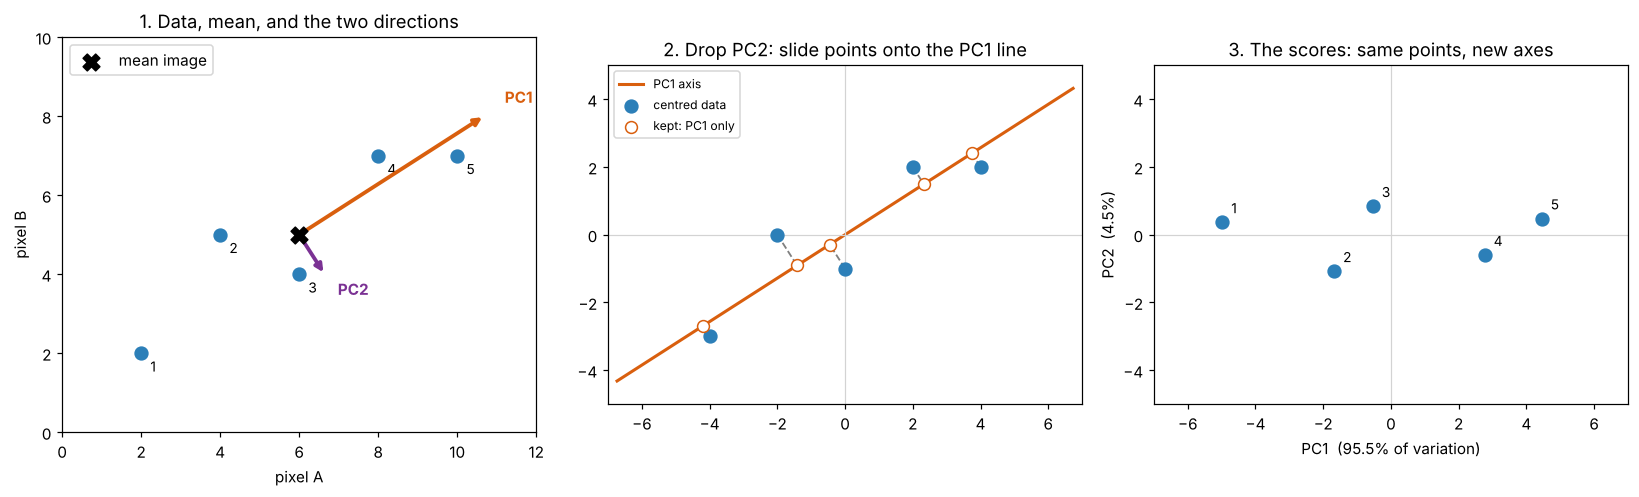

In [10]:
# A2.9: three pictures of the same 5 points
c_data, c_pc1, c_pc2 = "#2c7fb8", "#d95f0e", "#7b3294"
pc_ratio = np.array([lam1, lam2]) / (lam1 + lam2)
arrow_len = 1.5 * np.sqrt([lam1, lam2])              # arrow length shows the spread along each PC
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# (1) original points, the mean, and the two principal directions
ax = axes[0]
ax.scatter(tiny[:, 0], tiny[:, 1], s=70, color=c_data, zorder=3)
ax.scatter(*mu, marker="X", s=120, color="black", zorder=4, label="mean image")
for i, (a_i, b_i) in enumerate(tiny, start=1):
    ax.annotate(str(i), (a_i, b_i), textcoords="offset points", xytext=(6, -12), fontsize=9)
for k, (v, color, name) in enumerate([(v1_t, c_pc1, "PC1"), (v2_t, c_pc2, "PC2")]):
    ax.annotate("", xy=mu + arrow_len[k] * v, xytext=mu,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5))
    ax.text(*(mu + (arrow_len[k] + 0.6) * v), name, color=color, fontweight="bold")
ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.set_aspect("equal")
ax.set_xlabel("pixel A")
ax.set_ylabel("pixel B")
ax.set_title("1. Data, mean, and the two directions")
ax.legend(loc="upper left")

# (2) centred data; what happens when we keep only PC1
ax = axes[1]
t = np.array([-8, 8])
ax.plot(t * v1_t[0], t * v1_t[1], color=c_pc1, lw=2, label="PC1 axis")
projected = (Xc_t @ v1_t)[:, None] * v1_t[None, :]    # each point slid onto the PC1 line
for p_orig, p_proj in zip(Xc_t, projected):
    ax.plot([p_orig[0], p_proj[0]], [p_orig[1], p_proj[1]], "--", color="grey", lw=1.2)
ax.scatter(Xc_t[:, 0], Xc_t[:, 1], s=70, color=c_data, zorder=3, label="centred data")
ax.scatter(projected[:, 0], projected[:, 1], s=60, facecolor="white", edgecolor=c_pc1, zorder=3,
           label="kept: PC1 only")
ax.axhline(0, color="lightgrey", lw=0.8)
ax.axvline(0, color="lightgrey", lw=0.8)
ax.set_xlim(-7, 7)
ax.set_ylim(-5, 5)
ax.set_aspect("equal")
ax.set_title("2. Drop PC2: slide points onto the PC1 line")
ax.legend(loc="upper left", fontsize=8)

# (3) the scores: the same points, drawn with PC1 and PC2 as the axes
ax = axes[2]
ax.scatter(Z_t[:, 0], Z_t[:, 1], s=70, color=c_data, zorder=3)
for i, (z1, z2) in enumerate(Z_t, start=1):
    ax.annotate(str(i), (z1, z2), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.axhline(0, color="lightgrey", lw=0.8)
ax.axvline(0, color="lightgrey", lw=0.8)
ax.set_xlim(-7, 7)
ax.set_ylim(-5, 5)
ax.set_aspect("equal")
ax.set_xlabel(f"PC1  ({pc_ratio[0] * 100:.1f}% of variation)")
ax.set_ylabel(f"PC2  ({pc_ratio[1] * 100:.1f}%)")
ax.set_title("3. The scores: same points, new axes")

plt.tight_layout()
plt.show()

**How to read these three graphs**

1. **Graph 1:** the **PC1 arrow** points along the long axis of the cloud, the direction in which the images differ the most.
   Its numbers $v_1 \approx (0.84,\ 0.54)$ are both positive: pixels A and B get brighter *together*, so PC1 is "overall brightness".
   The **PC2 arrow** is perpendicular, $v_2 \approx (0.54,\ -0.84)$: one pixel up while the other goes down, a *contrast* between the pixels.
2. **Graph 2:** keeping only PC1 means sliding every point along its dashed line onto the PC1 line.
   The dashed lines are the information lost. Their total squared length is $(n-1)\lambda_2$ (checked in A2.8), which is small here.
3. **Graph 3:** PCA is a **rotation of the axes**. The scores are the same five points, now measured along PC1 (x) and PC2 (y).
   The cloud is wide in x ($\lambda_1 \approx 13.85$) and thin in y ($\lambda_2 \approx 0.65$), so PC1 alone is already
   about 96% of the story. Distances between points are identical in graphs 1 and 3: nothing is lost until we drop an axis.

**The Pokémon case is the same, with 1,728 axes instead of 2.** We can only draw the first two principal axes, which is exactly why the PC1 / PC2 graph is useful.

## A3: Load the images
Our helper `pre_process_image` replaces transparent areas with white, makes the image RGB, and shrinks it
to a square without stretching it. We keep each image as an array of numbers between 0 and 255.

In [11]:
# A3: load a few images per Pokémon
images, labels, names = [], [], []

for species_folder in sorted(IMAGE_DIR.iterdir()):
    if not species_folder.is_dir():
        continue
    for path in sorted(species_folder.glob("*.jpeg"))[:N_PER_SPECIES]:
        small = pre_process_image(path, IMAGE_SIZE, (255, 255, 255))
        images.append(np.asarray(small))      # shape (24, 24, 3)
        labels.append(species_folder.name)
        names.append(path.stem)

images = np.array(images)
labels = np.array(labels)

print("Number of images:", len(images))
print("Shape of images :", images.shape, " -> (how many, height, width, colours)")
for species in COLORS:
    print(f"  {species:<11}", int(np.sum(labels == species)), "images")

Number of images: 18
Shape of images : (18, 24, 24, 3)  -> (how many, height, width, colours)
  bulbasaur   6 images
  charmander  6 images
  pikachu     6 images


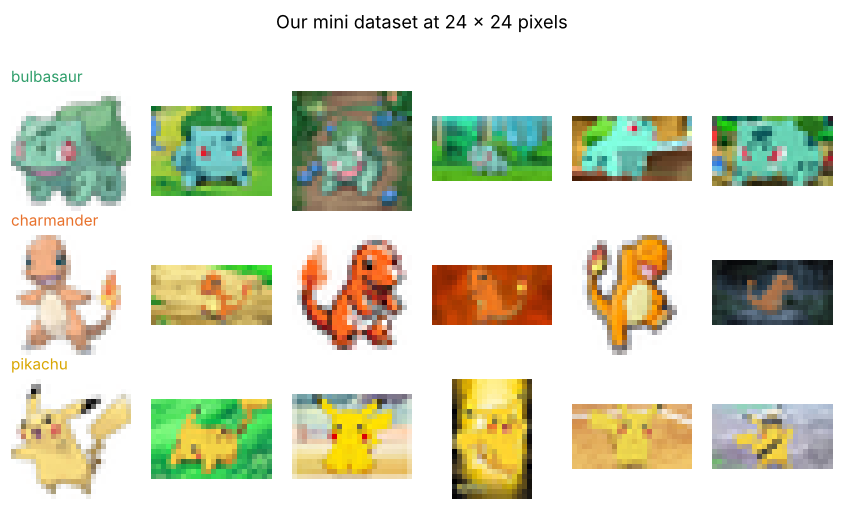

In [12]:
# Look at the data BEFORE doing any maths
species_list = list(COLORS)
fig, axes = plt.subplots(len(species_list), N_PER_SPECIES, figsize=(N_PER_SPECIES * 1.3, len(species_list) * 1.5))

for row, species in enumerate(species_list):
    imgs = images[labels == species]
    for col in range(N_PER_SPECIES):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(imgs):
            ax.imshow(imgs[col], interpolation="nearest")   # "nearest" keeps the pixels sharp
    axes[row, 0].set_title(species, loc="left", fontsize=10, color=COLORS[species])

fig.suptitle(f"Our mini dataset at {IMAGE_SIZE} x {IMAGE_SIZE} pixels", y=1.02)
plt.tight_layout()
plt.show()

## A4: Turn every image into one row of numbers
A computer does not see a Pokémon, it sees a grid of pixels, and each pixel has 3 numbers (red, green, blue).

> 24 pixels × 24 pixels × 3 colours = **1,728 numbers per image**

We flatten each image into one long row and stack the rows. This table is the **data matrix `X`**:
**one row per image, one column per pixel value.** Every column is a *feature*, so we have 1,728 features.
Dimensionality reduction means: *use far fewer than 1,728 numbers per image.*

In [13]:
# A4: build the data matrix X
n_images = len(images)

X = images.reshape(n_images, -1) / 255.0     # flatten each image, scale 0-255 -> 0-1

print("X shape:", X.shape, " -> (images, features)")
print("First 8 numbers of image 0:", np.round(X[0, :8], 2))

X shape: (18, 1728)  -> (images, features)
First 8 numbers of image 0: [1. 1. 1. 1. 1. 1. 1. 1.]


## A5: Centre the data
Subtract the **mean image** (the average of all images) from every image.
After this, each image describes *how it differs from the average*, which is what PCA studies.

$$\mu_j=\frac{1}{n}\sum_{i=1}^{n}x_{ij}\qquad\qquad X_c=X-\mathbf{1}\mu^{\top}$$

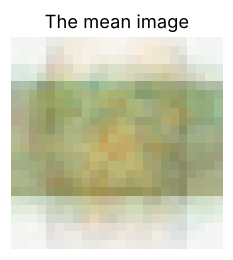

In [14]:
# A5: centre the data
mean_image = X.mean(axis=0)         # average of every column -> one "average Pokémon"
X_centered = X - mean_image

plt.figure(figsize=(2.5, 2.5))
plt.imshow(mean_image.reshape(IMAGE_SIZE, IMAGE_SIZE, 3), interpolation="nearest")
plt.title("The mean image")
plt.axis("off")
plt.show()

## A6: Covariance matrix
**Variance** = how much one pixel's values spread out across the images.
**Covariance** = whether two pixels move *together* (both get brighter in the same images).

The covariance matrix is a table with the covariance of **every pixel with every other pixel**:
1,728 features → a 1,728 × 1,728 table.

$$C=\frac{1}{n-1}\,X_c^{\top}X_c\qquad (p\times n)(n\times p)=(p\times p)$$

In [15]:
# A6: covariance matrix
n_features = X_centered.shape[1]
cov_matrix = (X_centered.T @ X_centered) / (n_images - 1)

print("Covariance matrix shape:", cov_matrix.shape)
print("Same as NumPy's np.cov? ", np.allclose(cov_matrix, np.cov(X_centered, rowvar=False)))

Covariance matrix shape: (1728, 1728)
Same as NumPy's np.cov?  True


## A7: Eigen-decomposition: finding the principal components
This is the heart of PCA.

$$C\,v_k=\lambda_k\,v_k$$

- An **eigenvector** of the covariance matrix is a direction in "pixel space" along which the images spread out a lot.
- Its **eigenvalue** says *how much* spread there is along that direction.

We sort them from biggest to smallest. The eigenvector with the biggest eigenvalue is **PC1**
(the first principal component), then PC2, and so on.

In [16]:
# A7: eigenvectors and eigenvalues
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)    # eigh is meant for symmetric matrices

order = np.argsort(eigenvalues)[::-1]                     # biggest first
eigenvalues = np.clip(eigenvalues[order], 0, None)        # tiny negatives are rounding noise
eigenvectors = eigenvectors[:, order]                     # each COLUMN is one direction

print("eigenvectors shape:", eigenvectors.shape, " -> one direction per column")
print("Biggest 3 eigenvalues:", np.round(eigenvalues[:3], 3))

eigenvectors shape: (1728, 1728)  -> one direction per column
Biggest 3 eigenvalues: [33.464 22.707 11.851]


In [17]:
# The same directions found a second way: SVD (still NumPy only)
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
svd_variances = S ** 2 / (n_images - 1)              # singular values -> variances

n_real = n_images - 1                                # only these many directions carry variation
print("Same variances as the eigen-decomposition?",
      np.allclose(svd_variances[:n_real], eigenvalues[:n_real]))
print("Same top-2 directions (ignoring sign)?     ",
      np.allclose(np.abs(Vt[:2]), np.abs(eigenvectors[:, :2].T), atol=1e-6))

Same variances as the eigen-decomposition? True
Same top-2 directions (ignoring sign)?      True


## A8: Explained variance ratio and scree plot
How much of the total variation does each component carry? That share is the **explained variance ratio**:
each eigenvalue divided by the sum of all eigenvalues. A **scree plot** shows these shares, and the
running total tells us how many components we need.

$$\mathrm{EVR}_k=\frac{\lambda_k}{\sum_{j}\lambda_j}$$

In [18]:
# A8: explained variance ratio
explained = eigenvalues / eigenvalues.sum()               # share of the total spread

for i in range(5):
    print(f"PC{i + 1}: {explained[i] * 100:5.1f}% of the variation")
print(f"PC1 + PC2 together: {explained[:2].sum() * 100:.1f}%")

PC1:  28.4% of the variation
PC2:  19.3% of the variation
PC3:  10.1% of the variation
PC4:   6.7% of the variation
PC5:   6.2% of the variation
PC1 + PC2 together: 47.7%


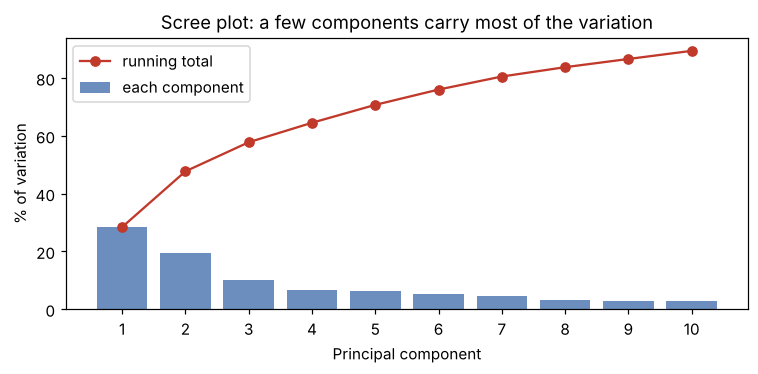

In [19]:
# Scree plot
fig, ax = plt.subplots(figsize=(7, 3.5))

ax.bar(range(1, 11), explained[:10] * 100, color="#6c8ebf", label="each component")
ax.plot(range(1, 11), np.cumsum(explained[:10]) * 100, "o-", color="#c0392b", label="running total")

ax.set_xlabel("Principal component")
ax.set_ylabel("% of variation")
ax.set_xticks(range(1, 11))
ax.set_title("Scree plot: a few components carry most of the variation")
ax.legend()
plt.tight_layout()
plt.show()

### What do the principal components look like?
Each eigenvector has 1,728 numbers, one per pixel value, so we can fold it back into a 24 × 24 picture.
Researchers working with faces call these **eigenfaces**. Ours are **eigen-Pokémon**.

Do not expect to see a Pokémon: because our backgrounds differ so much, the first components look like
colourful blobs and bands (for example, a green or blue border versus a plain one). That is what dominates the variation.

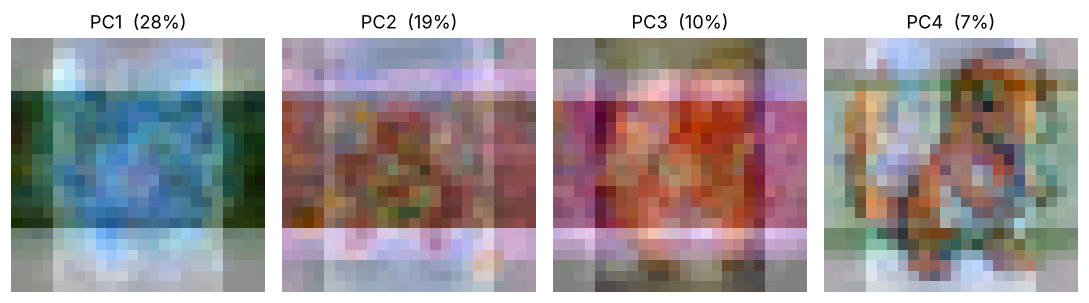

In [20]:
# Show the first 4 principal components as pictures
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))

for i, ax in enumerate(axes):
    pc = eigenvectors[:, i].reshape(IMAGE_SIZE, IMAGE_SIZE, 3)
    pc = (pc - pc.min()) / (pc.max() - pc.min())          # rescale to 0-1 so it can be drawn
    ax.imshow(pc, interpolation="nearest")
    ax.set_title(f"PC{i + 1}  ({explained[i] * 100:.0f}%)")
    ax.axis("off")

plt.tight_layout()
plt.show()

## A9: Project the data onto the top-k components
Now the dimensionality reduction itself. We keep only the first **k = 2** directions (PC1 and PC2) and measure
**how much of each direction every image contains.** Those 2 measurements are the new coordinates.

> 1,728 numbers per image → **2 numbers per image**

In code that is one matrix multiplication: `Z = X_centered @ W`.

$$Z=X_c\,W\qquad (n\times p)(p\times 2)=(n\times 2)$$

In [21]:
# A9: project the images onto PC1 and PC2
W = eigenvectors[:, :2]            # the 2 directions we keep, shape (1728, 2)
Z_pca = X_centered @ W             # new coordinates, shape (n_images, 2)

print("Before:", X.shape, " -> 1,728 numbers per image")
print("After :", Z_pca.shape, " -> 2 numbers per image")
print("Image 0 is now just:", np.round(Z_pca[0], 2))

Before: (18, 1728)  -> 1,728 numbers per image
After : (18, 2)  -> 2 numbers per image
Image 0 is now just: [ 0.01 -2.87]


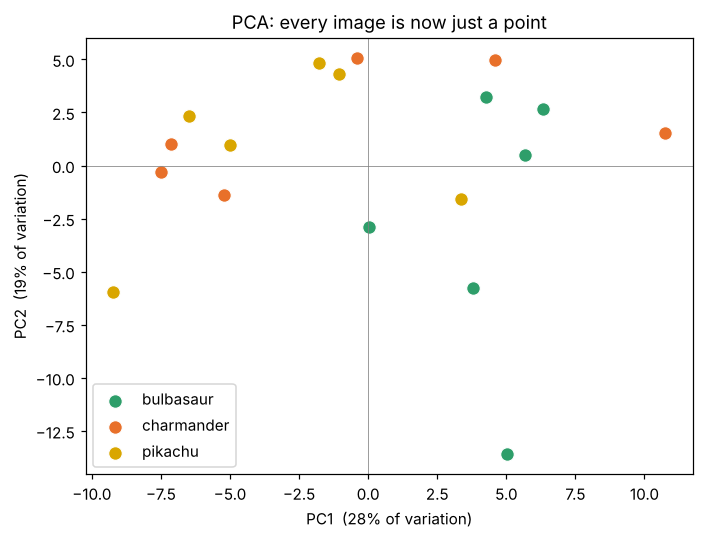

In [22]:
# x-y graph of all images
fig, ax = plt.subplots(figsize=(6.5, 5))

for species in species_list:
    mask = labels == species
    ax.scatter(Z_pca[mask, 0], Z_pca[mask, 1], s=80, color=COLORS[species],
               edgecolor="white", linewidth=0.8, label=species)

ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)
ax.set_xlabel(f"PC1  ({explained[0] * 100:.0f}% of variation)")
ax.set_ylabel(f"PC2  ({explained[1] * 100:.0f}% of variation)")
ax.set_title("PCA: every image is now just a point")
ax.legend()
plt.tight_layout()
plt.show()

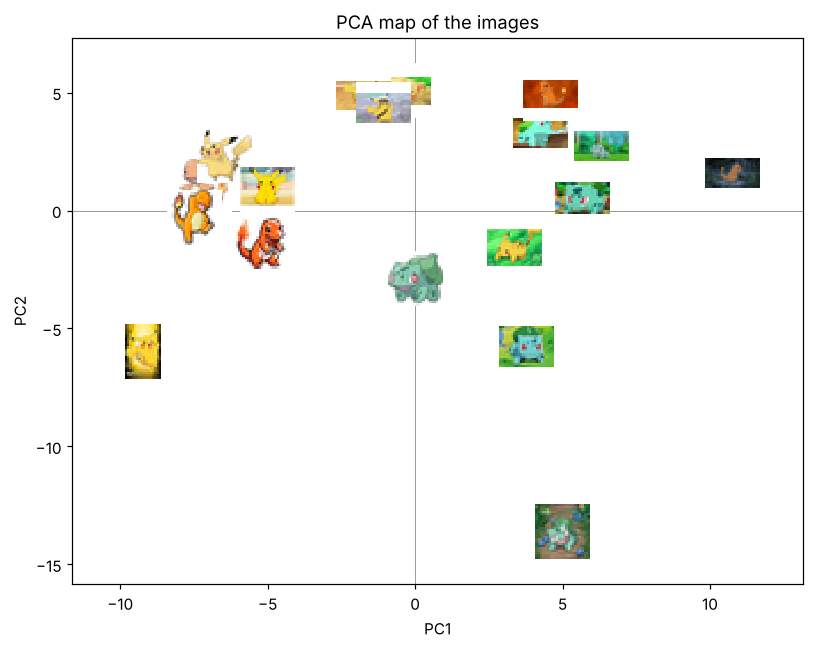

In [23]:
# Same graph, but showing the actual images, so we can SEE why images land where they do
def scatter_with_thumbnails(ax, Z, imgs, zoom=1.5):
    ax.scatter(Z[:, 0], Z[:, 1], alpha=0)               # invisible points just set the axis range
    for (x, y), img in zip(Z, imgs):
        box = AnnotationBbox(OffsetImage(img, zoom=zoom, interpolation="nearest"), (x, y), frameon=False)
        ax.add_artist(box)
    ax.margins(0.12)

fig, ax = plt.subplots(figsize=(7.5, 6))
scatter_with_thumbnails(ax, Z_pca, images)
ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA map of the images")
plt.tight_layout()
plt.show()

**What to notice:** which images sit close together? Look at their *backgrounds and overall colour*
as well as the Pokémon. Roughly, plain or light backgrounds land on one side of PC1 and green scenery on the other.
PCA never saw the labels, it only compared pixel values.

## A10: Reading the PC1 / PC2 graph: what do the axes mean?
The graph in A9 shows **scores**. To understand it, we need to connect each score to the **loadings** (the eigenvectors).

| | **Scores** | **Loadings** (eigenvectors) |
|---|---|---|
| What it is | $Z = X_c W$, one row per image | $W$, one column per principal component |
| Size here | n × 2 (one point per image) | 1,728 × 2 (one number per pixel value) |
| Tells you | *where* each image sits on the graph | *what* each axis means in pixel terms |
| Looks like | a dot on the x-y graph | a 24 × 24 picture (eigen-Pokémon) |

### A10.1 One score is a sum of 1,728 products
The tiny example computed $z_1 = dx \cdot v_{1x} + dy \cdot v_{1y}$ (2 terms).
For a Pokémon image it is the same formula with 1,728 terms:
$$z_{i1}=\sum_{j=1}^{p}\,(x_{ij}-\mu_j)\,v_{1j}$$

In [24]:
# A10.1: compute ONE score term by term
img_id = int(np.argmax(np.abs(Z_pca[:, 0])))        # the image with the largest PC1 score, so the numbers are easy to see
v1 = eigenvectors[:, 0]
start = n_features // 2                              # look at a few pixel values from the middle of the image

print(f"Image {img_id} ({names[img_id]}):  z1 = sum of {n_features} products  (x - mean) * v1")
print(f"{'pixel':>6}{'x':>9}{'mean':>9}{'x - mean':>11}{'v1':>9}{'product':>10}")
for j in range(start, start + 5):
    print(f"{j:>6}{X[img_id, j]:>9.3f}{mean_image[j]:>9.3f}{X_centered[img_id, j]:>11.3f}{v1[j]:>9.3f}"
          f"{X_centered[img_id, j] * v1[j]:>10.4f}")
print(f"{'...':>6}   ({n_features - 5} more rows)")

terms = X_centered[img_id] * v1
print(f"sum of all {n_features} products : {terms.sum():+.4f}")
print(f"Z_pca[{img_id}, 0] from A9       : {Z_pca[img_id, 0]:+.4f}   <- the same number")
print()
print("Each product is tiny, but 1,728 of them add up. Positive products push the image to the right on the graph, negative ones to the left.")

Image 11 (charmander_06):  z1 = sum of 1728 products  (x - mean) * v1
 pixel        x     mean   x - mean       v1   product
   864    0.118    0.707     -0.590   -0.041    0.0240
   865    0.169    0.729     -0.561   -0.036    0.0204
   866    0.149    0.545     -0.396   -0.055    0.0218
   867    0.149    0.710     -0.561   -0.033    0.0187
   868    0.224    0.693     -0.469   -0.028    0.0134
   ...   (1723 more rows)
sum of all 1728 products : +10.7560
Z_pca[11, 0] from A9       : +10.7560   <- the same number

Each product is tiny, but 1,728 of them add up. Positive products push the image to the right on the graph, negative ones to the left.


In [25]:
# A10.2: the three facts from the tiny example also hold for the real data
lhs = cov_matrix @ v1
rhs = eigenvalues[0] * v1
print("C v1 = lambda1 v1 ?                        ", np.allclose(lhs, rhs, atol=1e-8))
print(f"lambda1                                     = {eigenvalues[0]:.4f}")
print(f"variance of the PC1 scores                  = {Z_pca[:, 0].var(ddof=1):.4f}   (equal to lambda1)")
print(f"variance of the PC2 scores                  = {Z_pca[:, 1].var(ddof=1):.4f}   (equal to lambda2 = {eigenvalues[1]:.4f})")
print(f"correlation between PC1 and PC2 scores      = {abs(np.corrcoef(Z_pca[:, 0], Z_pca[:, 1])[0, 1]):.6f}   (uncorrelated)")
print(f"v1 . v2                                     = {abs(float(eigenvectors[:, 0] @ eigenvectors[:, 1])):.6f}   (perpendicular)")

C v1 = lambda1 v1 ?                         True
lambda1                                     = 33.4644
variance of the PC1 scores                  = 33.4644   (equal to lambda1)
variance of the PC2 scores                  = 22.7071   (equal to lambda2 = 22.7071)
correlation between PC1 and PC2 scores      = 0.000000   (uncorrelated)
v1 . v2                                     = 0.000000   (perpendicular)


### A10.3 Walk along PC1 and PC2
What does a high or low score *mean*? Start at the mean image and move $s$ standard deviations along one principal component:
$$\text{image}(s)=\mu + s\,\sqrt{\lambda_k}\;v_k$$

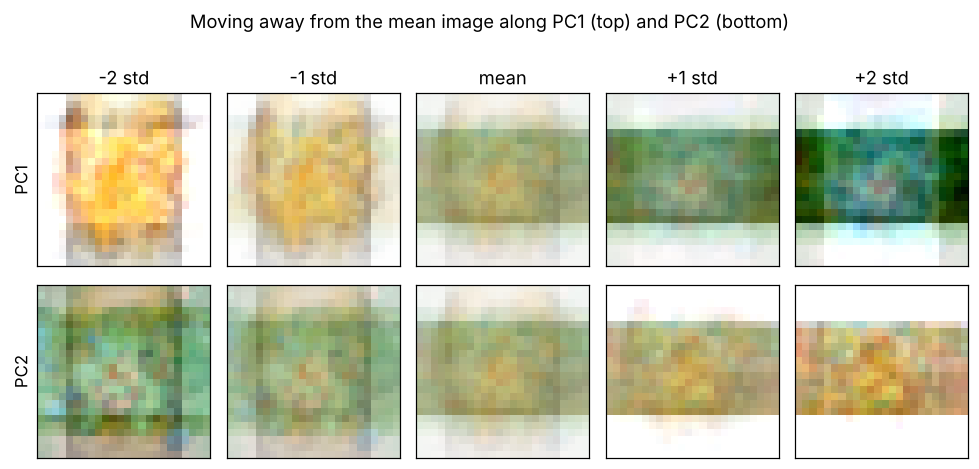

In [26]:
# A10.3: mean image +/- 1 and 2 standard deviations along PC1 (top) and PC2 (bottom)
steps = [-2, -1, 0, 1, 2]
fig, axes = plt.subplots(2, len(steps), figsize=(9, 4.4))

for row, pc in enumerate([0, 1]):
    sigma = np.sqrt(eigenvalues[pc])
    for col, s in enumerate(steps):
        walked = mean_image + s * sigma * eigenvectors[:, pc]
        ax = axes[row, col]
        ax.imshow(np.clip(walked.reshape(IMAGE_SIZE, IMAGE_SIZE, 3), 0, 1), interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title("mean" if s == 0 else f"{s:+d} std")
    axes[row, 0].set_ylabel(f"PC{pc + 1}", fontsize=11)

plt.suptitle("Moving away from the mean image along PC1 (top) and PC2 (bottom)", y=1.0)
plt.tight_layout()
plt.show()

### A10.4 Which images have the lowest and highest scores?

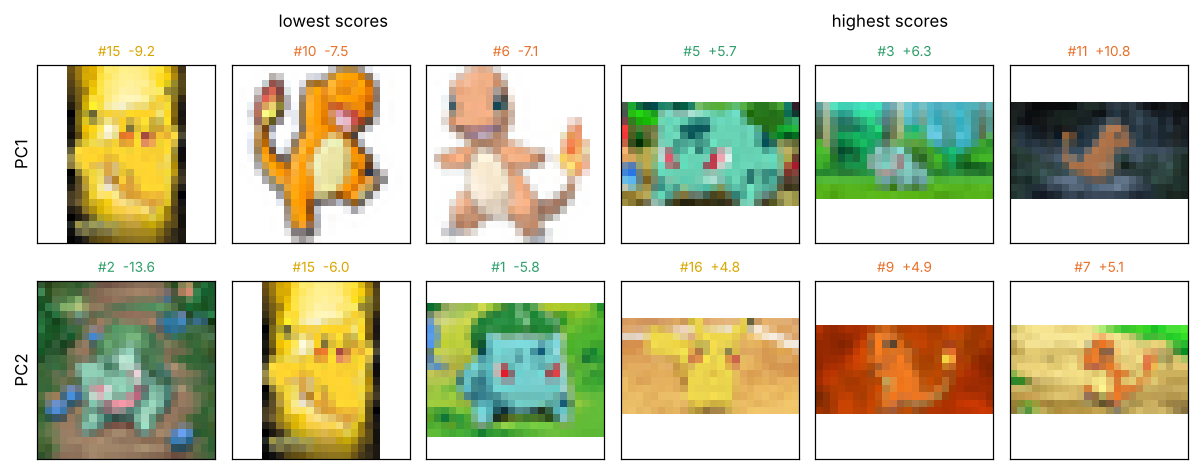

In [27]:
# A10.4: the 3 images with the lowest and the 3 with the highest score on PC1 and PC2
fig, axes = plt.subplots(2, 6, figsize=(11, 4.2))

for row, pc in enumerate([0, 1]):
    ranking = np.argsort(Z_pca[:, pc])
    chosen = list(ranking[:3]) + list(ranking[-3:])
    for col, idx in enumerate(chosen):
        ax = axes[row, col]
        ax.imshow(images[idx], interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"#{idx}  {Z_pca[idx, pc]:+.1f}", fontsize=9, color=COLORS[labels[idx]])
    axes[row, 0].set_ylabel(f"PC{pc + 1}", fontsize=11)

fig.text(0.28, 1.0, "lowest scores", ha="center", fontsize=11)
fig.text(0.74, 1.0, "highest scores", ha="center", fontsize=11)
plt.tight_layout()
plt.show()

### A10.5 The labelled x-y graph and the score table
Every dot carries the image number, so the picture and the table can be matched.

  #  image         species          PC1     PC2
 15  pikachu_04    pikachu        -9.23   -5.96
 10  charmander_05 charmander     -7.48   -0.30
  6  charmander_01 charmander     -7.14    1.02
 12  pikachu_01    pikachu        -6.47    2.34
  8  charmander_03 charmander     -5.23   -1.39
 14  pikachu_03    pikachu        -5.01    0.96
 16  pikachu_05    pikachu        -1.76    4.83
 17  pikachu_06    pikachu        -1.07    4.29
  7  charmander_02 charmander     -0.39    5.08
  0  bulbasaur_01  bulbasaur       0.01   -2.87
 13  pikachu_02    pikachu         3.37   -1.55
  1  bulbasaur_02  bulbasaur       3.79   -5.77
  4  bulbasaur_05  bulbasaur       4.27    3.23
  9  charmander_04 charmander      4.58    4.95
  2  bulbasaur_03  bulbasaur       5.01  -13.60
  5  bulbasaur_06  bulbasaur       5.67    0.52
  3  bulbasaur_04  bulbasaur       6.33    2.67
 11  charmander_06 charmander     10.76    1.56


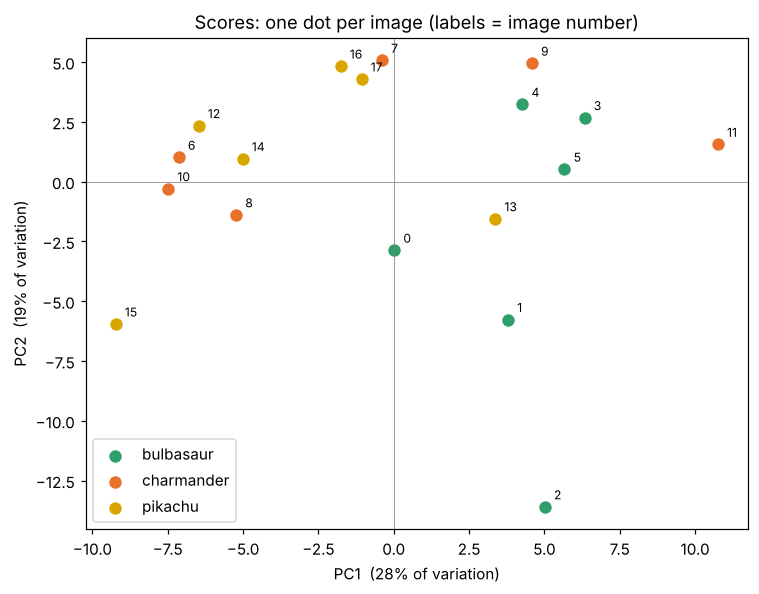

In [28]:
# A10.5: labelled scores graph + the numbers behind it
fig, ax = plt.subplots(figsize=(7, 5.5))
for species in species_list:
    mask = labels == species
    ax.scatter(Z_pca[mask, 0], Z_pca[mask, 1], s=80, color=COLORS[species],
               edgecolor="white", linewidth=0.8, label=species)
for i, (z1, z2) in enumerate(Z_pca):
    ax.annotate(str(i), (z1, z2), textcoords="offset points", xytext=(6, 5), fontsize=8)
ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)
ax.set_xlabel(f"PC1  ({explained[0] * 100:.0f}% of variation)")
ax.set_ylabel(f"PC2  ({explained[1] * 100:.0f}% of variation)")
ax.set_title("Scores: one dot per image (labels = image number)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"{'#':>3}  {'image':<14}{'species':<12}{'PC1':>8}{'PC2':>8}")
for i in np.argsort(Z_pca[:, 0]):
    print(f"{i:>3}  {names[i]:<14}{labels[i]:<12}{Z_pca[i, 0]:>8.2f}{Z_pca[i, 1]:>8.2f}")

**What the graph, the walk and the extremes tell us (from our run):**

- **PC1 (x-axis, 28%).** Low scores are warm yellow or orange pictures (Pikachu, Charmander), often on plain or pale backgrounds. High scores are wide pictures with green or dark scenery and white bars above and below. Nine of the twelve Pikachu and Charmander images have a negative PC1 and all six Bulbasaur images are positive, so PC1 *loosely* separates "green" from "yellow / orange".
- **PC2 (y-axis, 19%).** High scores are wide, pale orange or yellow pictures; low scores are busy dark or green backgrounds that fill the frame. PC2 is harder to name than PC1, which is normal: later components describe smaller and more mixed differences.
- **Distance from the centre.** An image near (0, 0) looks like the mean image (image 0 has PC1 of about 0.01). Far-away images, such as #11 on the right or #2 at the bottom, are the most unusual ones in our set.
- **An honest catch.** Our resize step pads wide or tall pictures with white. PCA only sees pixel values, so those white bars count as variation too. Part of what PC1 and PC2 describe is the *shape of the picture*, not the Pokémon.

**How to use the x-y graph in practice**

1. Read an image's position (its scores).
2. Use the walk in A10.3 to translate "+2 on PC1" into a picture.
3. Check the extremes in A10.4 to confirm the story.
4. Remember that the two axes show only 28.4% + 19.3% = 47.7% of the variation, so dots that look close can still differ along PC3 and beyond.

## A11: Reconstruction: rebuilding an image from a few numbers
If 2 numbers are enough to place an image on a map, how much of the *picture* survives?
We can go backwards:

> **image ≈ mean image + (its coordinates) × (the directions we kept)**

The more components `k` we keep, the closer we get to the original.

$$\hat{X}=\mathbf{1}\mu^{\top}+Z_k\,W_k^{\top}$$

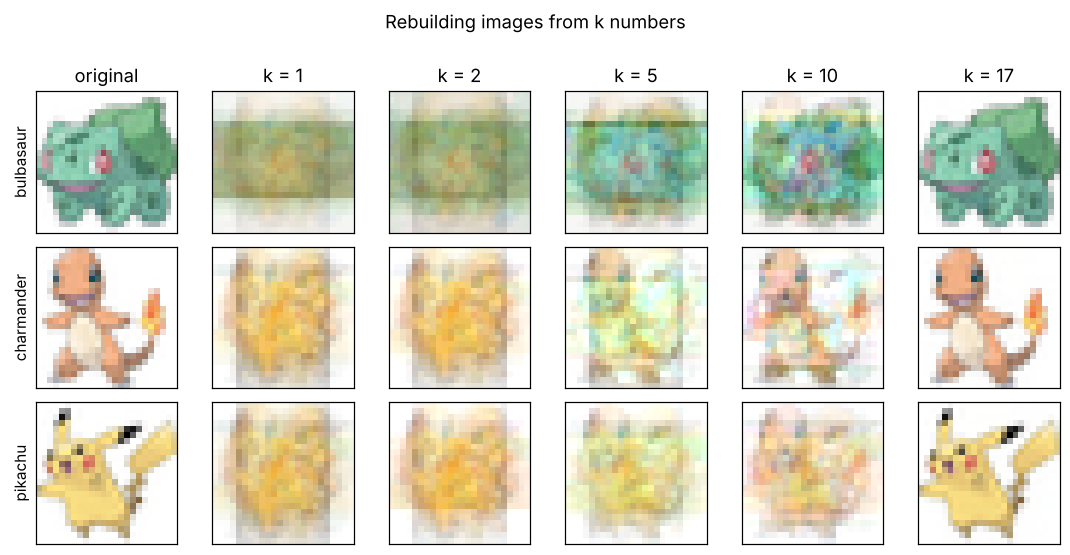

In [29]:
# A11: reconstruct three images with different numbers of components
def reconstruct(X_centered, k):
    W_k = eigenvectors[:, :k]
    Z_k = X_centered @ W_k                 # squash down to k numbers
    return mean_image + Z_k @ W_k.T        # blow back up to 1,728 numbers

k_values = [1, 2, 5, 10, n_images - 1]
examples = [np.where(labels == s)[0][0] for s in species_list]       # first image of each Pokémon

fig, axes = plt.subplots(len(examples), len(k_values) + 1, figsize=(10, 5))

for row, idx in enumerate(examples):
    axes[row, 0].imshow(images[idx], interpolation="nearest")
    axes[row, 0].set_title("original" if row == 0 else "")
    axes[row, 0].set_ylabel(labels[idx], fontsize=10)
    for col, k in enumerate(k_values, start=1):
        rebuilt = reconstruct(X_centered, k)[idx].reshape(IMAGE_SIZE, IMAGE_SIZE, 3)
        axes[row, col].imshow(np.clip(rebuilt, 0, 1), interpolation="nearest")
        if row == 0:
            axes[row, col].set_title(f"k = {k}")

for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle("Rebuilding images from k numbers", y=1.0)
plt.tight_layout()
plt.show()

Error with k=2 : 0.0336
Error with k=10: 0.0068
Error with k=17: 0.000000   (practically zero)

With k = 10 each image is stored with 10 numbers instead of 1728.


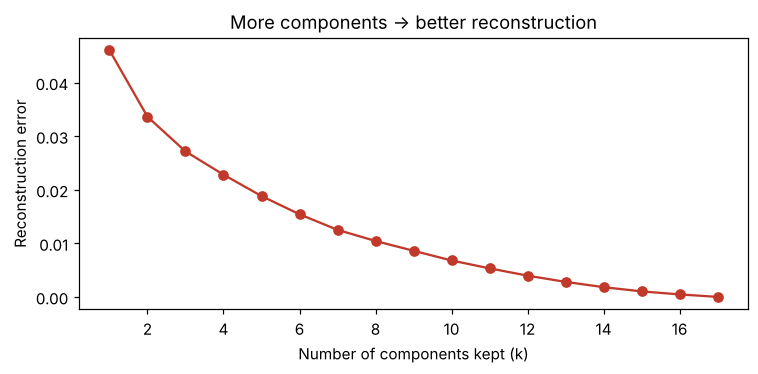

In [30]:
# How wrong is the rebuilt image? (average squared difference per pixel value)
ks = list(range(1, n_images))
errors = [np.mean((X - reconstruct(X_centered, k)) ** 2) for k in ks]

plt.figure(figsize=(7, 3.5))
plt.plot(ks, errors, "o-", color="#c0392b")
plt.xlabel("Number of components kept (k)")
plt.ylabel("Reconstruction error")
plt.title("More components -> better reconstruction")
plt.tight_layout()
plt.show()

print(f"Error with k=2 : {errors[1]:.4f}")
print(f"Error with k=10: {errors[9]:.4f}")
print(f"Error with k={ks[-1]}: {errors[-1]:.6f}   (practically zero)")
print()
print(f"With k = 10 each image is stored with 10 numbers instead of {X.shape[1]}.")

**Why does the error reach zero at the last k?** We only have a handful of images (18 with the default
settings), so after centring they span at most *(number of images − 1)* independent directions (17 here).
With real datasets of thousands of images you would keep a small *fraction* of the components and accept
a small error. That trade-off is **compression**.

## A12: Wrap the steps into one reusable function
Everything we just did fits in a short function. We will reuse it in Parts B and C on completely different data.

In [31]:
# A12: our own PCA as one function (NumPy only)
def my_pca(data, k):
    mean = data.mean(axis=0)                                  # A5: centre
    centered = data - mean
    cov = centered.T @ centered / (len(data) - 1)             # A6: covariance
    values, vectors = np.linalg.eigh(cov)                     # A7: eigen-decomposition
    order = np.argsort(values)[::-1]
    values = np.clip(values[order], 0, None)
    vectors = vectors[:, order]
    coords = centered @ vectors[:, :k]                        # A9: project onto top-k
    return mean, vectors, values, coords

# quick test: the function must give the same answer as the step-by-step version
_, _, _, Z_test = my_pca(X, 2)
print("Function matches our step-by-step result?", np.allclose(Z_test, Z_pca))

Function matches our step-by-step result? True


**End of Part A.** We built PCA with nothing but NumPy: centre → covariance → eigen-decomposition →
explained variance → projection → reconstruction. No scikit-learn was used.

---
# Part B: Comparative study (scikit-learn)
**No live coding here: just run the cells.** This is the first time scikit-learn appears. We use it for two things only:

1. **Proof:** does scikit-learn's PCA agree with the one we built by hand?
2. **Comparison:** how does PCA compare with **t-SNE** on the same images? And when does PCA fail?

In [32]:
# B0: scikit-learn, used for comparison only
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import silhouette_score

print("scikit-learn loaded. Our own PCA from Part A is the reference.")

scikit-learn loaded. Our own PCA from Part A is the reference.


## B1: Our PCA vs scikit-learn PCA
Three checks on the same data, with the **same number of components** (k = 10).

In [33]:
# B1: proof that our NumPy PCA agrees with scikit-learn's PCA
K = 10

# ours (Part A)
mean_ours, vectors_ours, values_ours, Z_ours = my_pca(X, K)
rebuilt_ours = mean_ours + Z_ours @ vectors_ours[:, :K].T
ratio_ours = values_ours / values_ours.sum()

# scikit-learn  (svd_solver="full" = exact maths; the default may pick a faster, approximate method)
pca_sk = PCA(n_components=K, svd_solver="full").fit(X)
Z_sk = pca_sk.transform(X)
rebuilt_sk = pca_sk.inverse_transform(Z_sk)

checks = [
    ("projected coordinates (ignore sign)", np.abs(Z_ours), np.abs(Z_sk)),
    ("explained variance ratio",            ratio_ours[:K], pca_sk.explained_variance_ratio_),
    ("reconstruction from k = 10",          rebuilt_ours, rebuilt_sk),
]

print(f"{'check':<38}{'result':<10}{'largest difference'}")
for name, ours, theirs in checks:
    diff = np.max(np.abs(ours - theirs))
    print(f"{name:<38}{'match' if diff < 1e-6 else 'DIFFERENT':<10}{diff:.1e}")

check                                 result    largest difference
projected coordinates (ignore sign)   match     8.3e-14
explained variance ratio              match     6.1e-16
reconstruction from k = 10            match     1.2e-14


Differences around 10⁻¹² are just computer rounding: **our PCA and scikit-learn's PCA give the same answer.**
(The sign of a component is arbitrary, a direction and its mirror are equally valid, so signs are ignored.)

## B2: PCA vs t-SNE (visualisation only)
PCA draws a **straight-line** projection and keeps the directions with the most spread.
**t-SNE** tries to keep each image's *nearest neighbours* close in the 2D picture. It can bend and stretch space,
so it is **non-linear**, and it is used only to *visualise*, not to compress.

method    trustworthiness   silhouette
PCA                 0.909       -0.044
t-SNE               0.880        0.033


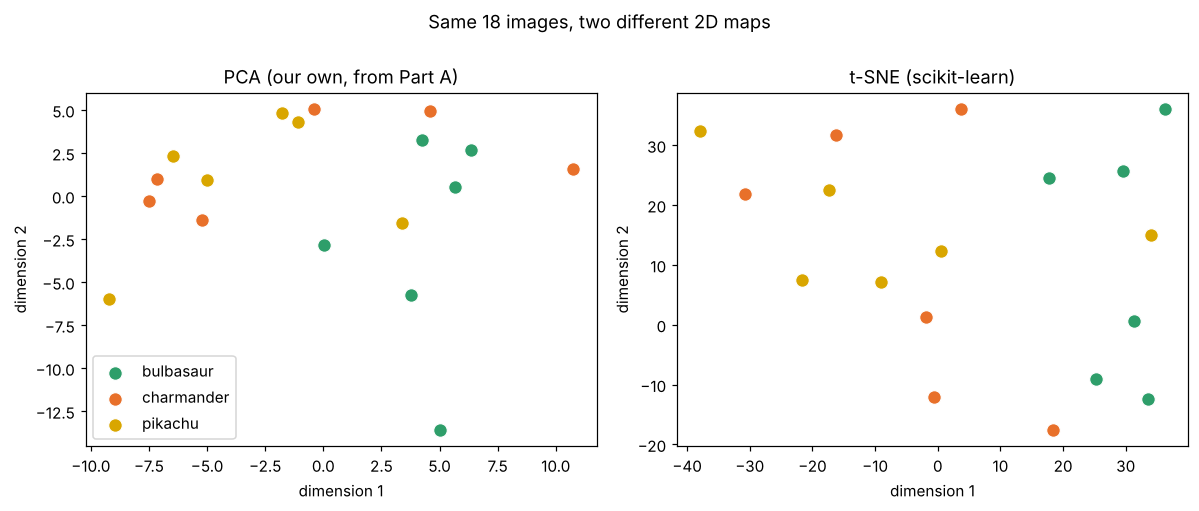

In [34]:
# B2: t-SNE on exactly the same data matrix X, next to our PCA map
tsne = TSNE(n_components=2, perplexity=5, init="pca", learning_rate="auto", random_state=RANDOM_STATE)
Z_tsne = tsne.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, Z, title in [(axes[0], Z_pca, "PCA (our own, from Part A)"), (axes[1], Z_tsne, "t-SNE (scikit-learn)")]:
    for species in species_list:
        mask = labels == species
        ax.scatter(Z[mask, 0], Z[mask, 1], s=80, color=COLORS[species],
                   edgecolor="white", linewidth=0.8, label=species)
    ax.set_title(title)
    ax.set_xlabel("dimension 1")
    ax.set_ylabel("dimension 2")
axes[0].legend()
plt.suptitle(f"Same {n_images} images, two different 2D maps", y=1.0)
plt.tight_layout()
plt.show()

# two simple scores for each map
print(f"{'method':<8} {'trustworthiness':>16} {'silhouette':>12}")
for name, Z in [("PCA", Z_pca), ("t-SNE", Z_tsne)]:
    print(f"{name:<8} {trustworthiness(X, Z, n_neighbors=5):>16.3f} {silhouette_score(Z, labels):>12.3f}")

- **Trustworthiness** (0 to 1): are images that were neighbours in the original pixel space still neighbours on the map? Higher is better.
- **Silhouette** (-1 to 1): are images of the *same Pokémon* closer to each other than to other Pokémon? Higher means tighter, better separated groups.

**How to read these numbers (from our run):**

- Both methods tell a **similar story**: light, plain backgrounds (the clean drawings) end up on one side and
  green scenery on the other. Neither fully separates the three Pokémon.
- The **silhouette scores are both close to 0**, so the Pokémon groups overlap in both maps.
  t-SNE is slightly higher, but with only a handful of images such a small gap should not be over-interpreted.
- **PCA kept the neighbourhoods a little better** (higher trustworthiness) in this run.

This is a realistic result: both methods only compare **pixel values**, and our pixels are dominated by backgrounds.
Separating Pokémon properly would need cleaner images (same background) or more advanced features.

| | **PCA** | **t-SNE** |
|---|---|---|
| Type | Linear (straight projection) | Non-linear (keeps neighbours close) |
| Same answer every run? | Yes | No, depends on settings such as perplexity |
| Do the axes mean something? | Yes, real directions in pixel space | No |
| Can we rebuild the images? | Yes (A11) | No |
| Can it place a *new* image? | Yes, reuse the same `W` | Not directly, the map must be recomputed |
| Speed | Very fast | Slow on large data |
| Best for | Understanding, compressing, speeding up models | Looking at clusters |

## B3: Linear vs non-linear: when does PCA fail?
PCA can only find **straight** directions. If the structure in the data is *curved*, a straight projection
squashes it flat and different groups land on top of each other. Classic example: **two rings**, one inside the other.
Here the 2D points are generated with NumPy, then reduced to a single number by our own PCA.

Silhouette of the two rings, PCA 1D : 0.180
Silhouette of the two rings, t-SNE  : 0.732


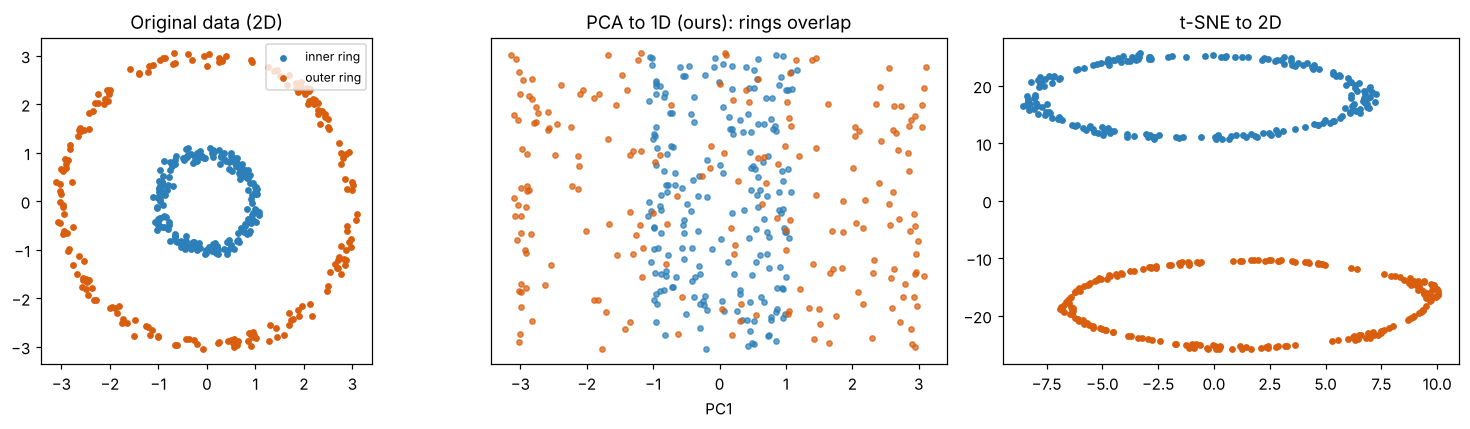

In [35]:
# B3: two concentric rings. PCA (ours) squashes them onto a line; t-SNE keeps the ring structure
rng = np.random.default_rng(RANDOM_STATE)
angles = rng.uniform(0, 2 * np.pi, 400)
radius = np.where(np.arange(400) < 200, 1.0, 3.0) + rng.normal(0, 0.08, 400)     # inner ring, outer ring
rings = np.column_stack([radius * np.cos(angles), radius * np.sin(angles)])
ring_labels = np.where(np.arange(400) < 200, "inner ring", "outer ring")
ring_colors = {"inner ring": "#2c7fb8", "outer ring": "#d95f0e"}

_, _, _, ring_pca = my_pca(rings, 1)                                              # our PCA, 2D -> 1D
ring_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(rings)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for name, color in ring_colors.items():
    m = ring_labels == name
    axes[0].scatter(rings[m, 0], rings[m, 1], s=12, color=color, label=name)
    axes[1].scatter(ring_pca[m, 0], rng.uniform(-0.3, 0.3, m.sum()), s=12, color=color, alpha=0.7)
    axes[2].scatter(ring_tsne[m, 0], ring_tsne[m, 1], s=12, color=color)
axes[0].set_title("Original data (2D)")
axes[0].set_aspect("equal")
axes[0].legend(loc="upper right", fontsize=8)
axes[1].set_title("PCA to 1D (ours): rings overlap")
axes[1].set_yticks([])
axes[1].set_xlabel("PC1")
axes[2].set_title("t-SNE to 2D")
plt.tight_layout()
plt.show()

print(f"Silhouette of the two rings, PCA 1D : {silhouette_score(ring_pca, ring_labels):.3f}")
print(f"Silhouette of the two rings, t-SNE  : {silhouette_score(ring_tsne, ring_labels):.3f}")

**What happened (from our run):** we reduce to **1 dimension** on purpose, because PCA from 2D to 2D would only
rotate the picture. Our PCA squashes the rings onto a line, the inner ring lands in the middle of the outer ring,
and the silhouette is low (about 0.18). t-SNE pulls the two rings apart cleanly (about 0.73).

This is a designed example (real data is rarely this clean), but it shows the key idea:
**PCA only finds straight directions**, so it cannot "unfold" curved structure. t-SNE can, but it gives up
meaningful axes and the ability to rebuild the data.

**Other situations where PCA struggles**

- **Curved structure** (like the rings): a straight projection cannot unfold it.
- **Features on very different scales** (for example seconds vs bytes): the large-number feature dominates, so we *standardise* first (Part C does this).
- **Important information in a weak direction:** PCA keeps the *largest variation*, which is not always the *most useful* variation for a task. In our Pokémon images, the biggest variation is the background.
- **Outliers:** one extreme data point can pull a component towards itself.

---
# Part C: Application: cybersecurity-style network data
Network monitoring produces records with *many* numbers per connection (bytes, packets, ports, connection rate...).
Analysts cannot look at 12 or 40 dimensions at once, so PCA is used to reduce them and to spot unusual traffic.

> **This data is synthetic (made up with NumPy) to keep the demo small and runnable.** It is *not* real attack data.
> The same code works on a real dataset (for example NSL-KDD or CIC-IDS) once its numeric columns are loaded into a table `X`.

In [36]:
# C1: a small synthetic "network flow" table with 12 features
rng = np.random.default_rng(RANDOM_STATE)
feature_names = ["duration", "src_bytes", "dst_bytes", "packets_in", "packets_out", "syn_count",
                 "fin_count", "unique_ports", "conn_per_min", "failed_logins", "avg_pkt_size", "retransmits"]

n_normal, n_attack = 300, 40
mixing = rng.normal(0, 1, size=(3, 12))                 # 3 hidden behaviours drive all 12 features
mixing[0, [1, 2, 3, 4, 10]] += 2.5                      # behaviour 1 = traffic volume
mixing[1, [5, 7, 8]] += 2.5                             # behaviour 2 = scanning many ports quickly
mixing[2, [9, 11]] += 2.5                               # behaviour 3 = login trouble

normal = rng.normal(0, [1.0, 0.3, 0.3], size=(n_normal, 3))
attack = rng.normal([0.0, 3.0, 0.5], [1.0, 0.5, 0.3], size=(n_attack, 3))        # port-scan-like behaviour
flows = np.vstack([normal, attack]) @ mixing + rng.normal(0, 0.6, size=(n_normal + n_attack, 12))
flow_labels = np.array(["normal"] * n_normal + ["attack-like"] * n_attack)

print("Table of flows:", flows.shape, " -> (connections, features)")
print("Features have very different scales, e.g. std of the first 4:", np.round(flows.std(axis=0)[:4], 2))

Table of flows: (340, 12)  -> (connections, features)
Features have very different scales, e.g. std of the first 4: [0.65 2.07 3.54 3.62]


12 features -> 2 components keep 78% of the variation
First 3 components keep           87%


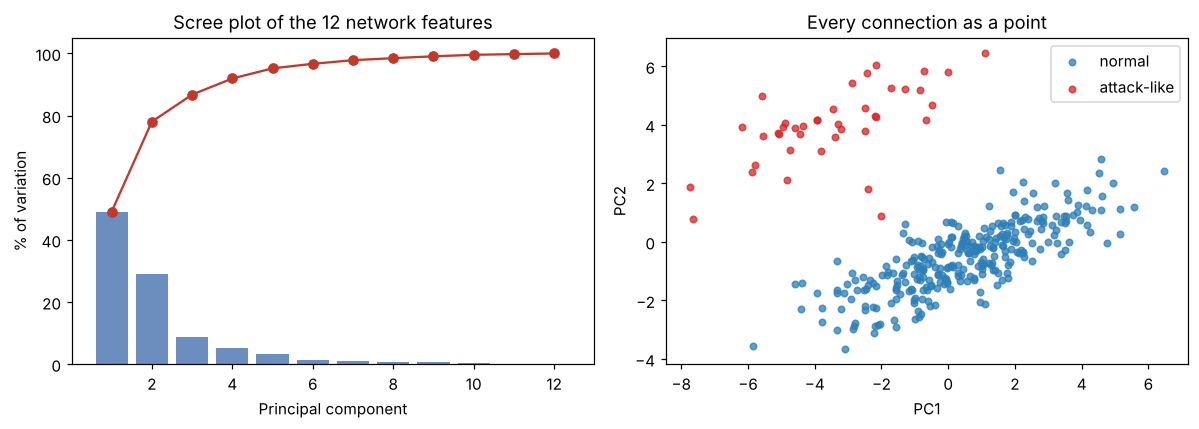

In [37]:
# C2: standardise (every feature gets mean 0, spread 1), then run OUR PCA
flows_std = (flows - flows.mean(axis=0)) / flows.std(axis=0)

_, flow_vectors, flow_values, flow_2d = my_pca(flows_std, 2)
flow_ratio = flow_values / flow_values.sum()

print(f"12 features -> 2 components keep {flow_ratio[:2].sum() * 100:.0f}% of the variation")
print(f"First 3 components keep           {flow_ratio[:3].sum() * 100:.0f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(range(1, 13), flow_ratio * 100, color="#6c8ebf")
axes[0].plot(range(1, 13), np.cumsum(flow_ratio) * 100, "o-", color="#c0392b")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("% of variation")
axes[0].set_title("Scree plot of the 12 network features")

for name, color in [("normal", "#2c7fb8"), ("attack-like", "#d62728")]:
    m = flow_labels == name
    axes[1].scatter(flow_2d[m, 0], flow_2d[m, 1], s=18, color=color, alpha=0.75, label=name)
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("Every connection as a point")
axes[1].legend()

plt.tight_layout()
plt.show()

**What to notice (from our run):**

- **12 features → 2 components keeps about 78% of the variation.** The scree plot bends sharply after 2 to 3 components,
  which tells us most of the 12 numbers are redundant (they all move with the same few hidden behaviours).
- The **attack-like connections stand out along PC2**, away from the normal cloud. In real monitoring such points
  are *anomalies* an analyst would look at first.
- **Standardising first mattered:** the raw features had very different spreads (see the printed standard deviations),
  and without standardising, the features with big numbers would dominate PC1 regardless of how useful they are.
- **Honest caveat:** the separation here is partly *by design*, because we built the data with a hidden scanning behaviour.
  Real attacks are messier, and PCA is a first look, not a detector.

---
## Real-life uses
We used Pokémon pictures because they are fun and small, but the same steps are used for:

- **Image compression and storage:** keep the top components, throw away the rest
- **Face recognition:** the classic *eigenfaces* method is exactly A5 to A9 on photos of faces
- **Noise removal:** noise lives in the weak components, so rebuilding from the strong ones cleans an image
- **Faster machine learning:** train a model on 50 PCA features instead of thousands of raw pixels
- **Medical and satellite imaging:** summarising very large images with a few numbers
- **Security monitoring:** reducing many network features to a few, to look for unusual traffic

> Real photographs are much bigger than 24 × 24, so in practice people use an optimised version of PCA (SVD)
> rather than building the full covariance matrix. The idea is identical.

## Checklist against the brief

| Requirement | Where |
|---|---|
| Pure Python (NumPy) | Part A uses NumPy only |
| Step-by-step formulas and matrix calculations | A1 (formula sheet), A2 (worked example by hand) |
| Centre data, compute covariance matrix | A5, A6 |
| Eigen-decomposition (or SVD) for the principal components | A7 (both ways) |
| Project data onto top-k components | A9 |
| Reading PC1 and PC2 on the x-y graph | A2.9 (tiny example), A10 (Pokémon images) |
| Explained variance ratio and scree plot | A8 |
| Reconstruction from the reduced representation | A11 |
| Comparison with `sklearn.decomposition.PCA` | B1 |
| Comparison with t-SNE (`sklearn.manifold.TSNE`, visualisation only) | B2 |
| Discussion: linear vs non-linear, when PCA fails | B2 table, B3 |
| Application on a cybersecurity-style dataset | Part C |

### Try it yourself
- Change `N_PER_SPECIES` to 4, then to 10: what happens to the maps?
- Change `IMAGE_SIZE` to 12 or 32: how do the reconstructions change?
- Change the `perplexity` of t-SNE: when do the groups fall apart?
- Add your own image to one of the folders and see where it lands.